In [2]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

Διαστάσεις: (256, 256)
Min τιμή: 0.0
Max τιμή: 255.0


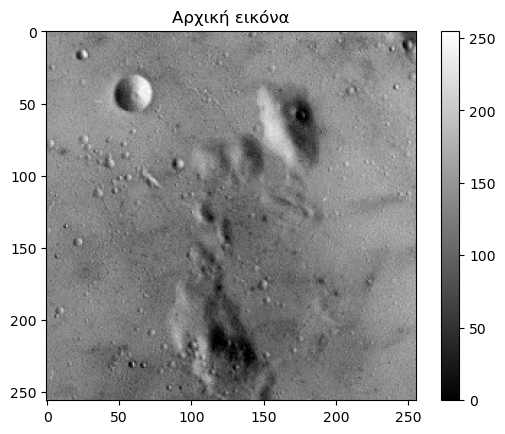

In [3]:
# Φόρτωση εικόνας ως grayscale
img = np.array(Image.open('moon.jpg').convert('L'), dtype=float)

# Εκτύπωση βασικών πληροφοριών
print(f"Διαστάσεις: {img.shape}")
print(f"Min τιμή: {img.min()}")
print(f"Max τιμή: {img.max()}")

# Εμφάνιση εικόνας
plt.imshow(img, cmap='gray')
plt.title('Αρχική εικόνα')
plt.colorbar()
plt.show()

In [4]:
# Γραμμικό stretching στο [0, 255]
f_min = img.min()
f_max = img.max()

img_stretched = (img - f_min) / (f_max - f_min) * 255

print(f"Min μετά stretching: {img_stretched.min()}")
print(f"Max μετά stretching: {img_stretched.max()}")

Min μετά stretching: 0.0
Max μετά stretching: 255.0


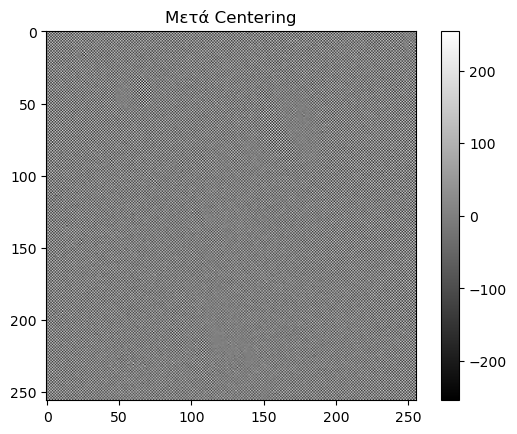

In [5]:
# Δημιουργία πλέγματος συντεταγμένων
M, N = img_stretched.shape
x = np.arange(M)   # 0,1,2,...,255
y = np.arange(N)   # 0,1,2,...,255
xx, yy = np.meshgrid(x, y, indexing='ij')

# Μάσκα (-1)^(x+y)
mask = (-1.0) ** (xx + yy)

# Εφαρμογή
img_centered = img_stretched * mask

# Εμφάνιση
plt.imshow(img_centered, cmap='gray')
plt.title('Μετά Centering')
plt.colorbar()
plt.show()

In [6]:
# 2D-DFT με μέθοδο γραμμών-στηλών
# Βήμα 1: 1D-DFT σε κάθε γραμμή
F_rows = np.fft.fft(img_centered, axis=1)

# Βήμα 2: 1D-DFT σε κάθε στήλη του αποτελέσματος
F = np.fft.fft(F_rows, axis=0)

print(f"Τύπος αποτελέσματος: {F.dtype}")
print(f"Διαστάσεις F: {F.shape}")

Τύπος αποτελέσματος: complex128
Διαστάσεις F: (256, 256)


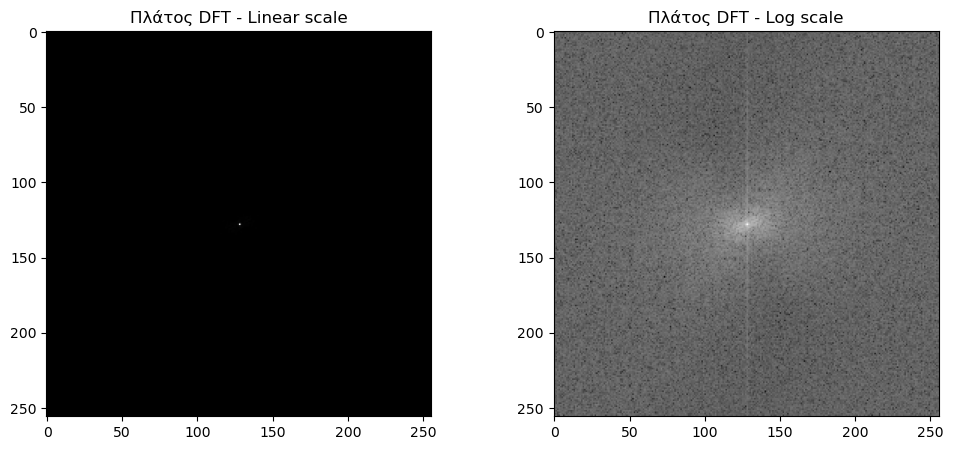

In [7]:
# Υπολογισμός πλάτους
magnitude = np.abs(F)

# Εμφάνιση και των δύο
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(magnitude, cmap='gray')
axes[0].set_title('Πλάτος DFT - Linear scale')

axes[1].imshow(np.log(1 + magnitude), cmap='gray')
axes[1].set_title('Πλάτος DFT - Log scale')

plt.show()

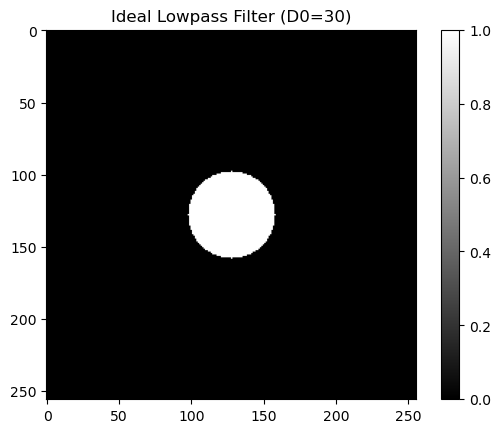

In [8]:
# Ακτίνα αποκοπής
D0 = 30

# Δημιουργία πλέγματος αποστάσεων από το κέντρο
u = np.arange(M) - M//2
v = np.arange(N) - N//2
uu, vv = np.meshgrid(u, v, indexing='ij')
D = np.sqrt(uu**2 + vv**2)

# Δημιουργία φίλτρου
H = (D <= D0).astype(float)

# Εμφάνιση φίλτρου
plt.imshow(H, cmap='gray')
plt.title(f'Ideal Lowpass Filter (D0={D0})')
plt.colorbar()
plt.show()

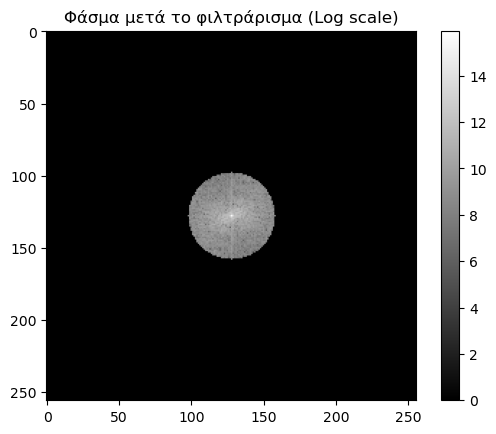

In [9]:
# Εφαρμογή φίλτρου στο πεδίο συχνοτήτων
G = F * H

# Εμφάνιση πλάτους φιλτραρισμένου φάσματος (log scale)
plt.imshow(np.log(1 + np.abs(G)), cmap='gray')
plt.title('Φάσμα μετά το φιλτράρισμα (Log scale)')
plt.colorbar()
plt.show()

In [10]:
# 2D-IDFT με μέθοδο γραμμών-στηλών
# Βήμα 1: 1D-IDFT σε κάθε στήλη
g_cols = np.fft.ifft(G, axis=0)

# Βήμα 2: 1D-IDFT σε κάθε γραμμή
g = np.fft.ifft(g_cols, axis=1)

# Κρατάμε μόνο το πραγματικό μέρος
g_real = np.real(g)

print(f"Min: {g_real.min():.2f}")
print(f"Max: {g_real.max():.2f}")

Min: -260.02
Max: 259.99


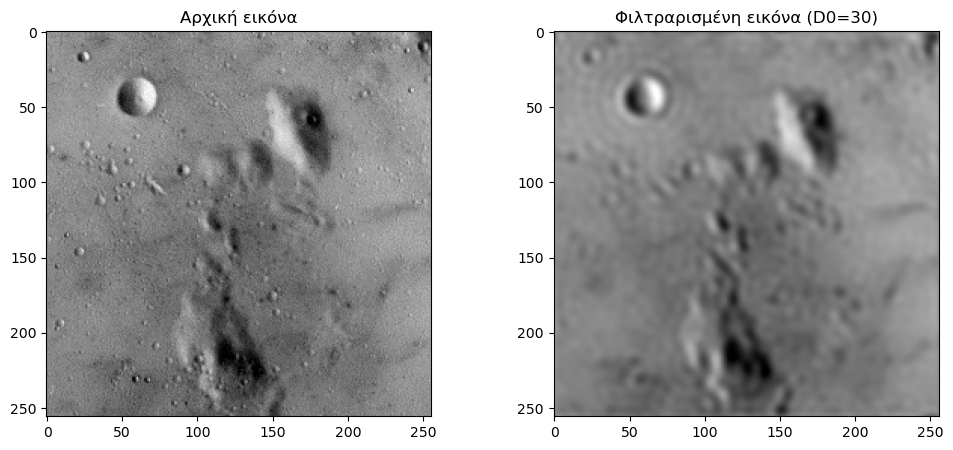

In [11]:
# Αναίρεση centering
g_uncentered = g_real * mask

# Clip στο [0, 255]
g_final = np.clip(g_uncentered, 0, 255)

# Εμφάνιση αρχικής και φιλτραρισμένης εικόνας
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(img, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Αρχική εικόνα')

axes[1].imshow(g_final, cmap='gray', vmin=0, vmax=255)
axes[1].set_title(f'Φιλτραρισμένη εικόνα (D0={D0})')

plt.show()

Το κατωπερατό φίλτρο αφαιρεί τις υψηλές συχνότητες που αντιστοιχούν σε ακμές και λεπτομέρειες.
Η ακτίνα D0=30D_0=30.
D0​=30 επιλέχθηκε ώστε να διατηρηθούν οι βασικές δομές της εικόνας.
Μικρότερο D0= περισσότερο θόλωμα, μεγαλύτερο D0​ = λιγότερο θόλωμα.
Το ringing effect οφείλεται στην απότομη αποκοπή του ιδανικού φίλτρου, φίλτρα Butterworth ή Gaussian το αποφεύγουν.